In [2]:
import pandas as pd
from google.colab import files

# Upload the CSV file
uploaded = files.upload()

# Get the uploaded filename automatically
filename = list(uploaded.keys())[0]

# Load the dataset
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Saving data_core.csv to data_core.csv
Dataset loaded successfully!
Dataset shape: (8000, 9)

Column names:
['Temparature', 'Humidity', 'Moisture', 'Soil Type', 'Crop Type', 'Nitrogen', 'Potassium', 'Phosphorous', 'Fertilizer Name']


In [3]:
# Create a copy of the original dataframe
df_engineered = df.copy()

# Feature 1: Total amount of N, P, and K
df_engineered["Total_Nutrients"] = (
    df_engineered["Nitrogen"]
    + df_engineered["Phosphorous"]
    + df_engineered["Potassium"]
)

# Feature 2: Difference between the highest and lowest nutrient values
df_engineered["NPK_Imbalance"] = (
    df_engineered[["Nitrogen", "Phosphorous", "Potassium"]].max(axis=1)
    - df_engineered[["Nitrogen", "Phosphorous", "Potassium"]].min(axis=1)
)

# Display the original and new features
print(df_engineered[
    [
        "Nitrogen",
        "Phosphorous",
        "Potassium",
        "Total_Nutrients",
        "NPK_Imbalance"
    ]
].head(10))

   Nitrogen  Phosphorous  Potassium  Total_Nutrients  NPK_Imbalance
0        37            0          0               37             37
1        12           36          0               48             36
2         7           30          9               46             23
3        22           20          0               42             22
4        35            0          0               35             35
5        12           13         10               35              3
6         9           10          0               19             10
7        41            0          0               41             41
8        21           18          0               39             21
9         9           30          7               46             23


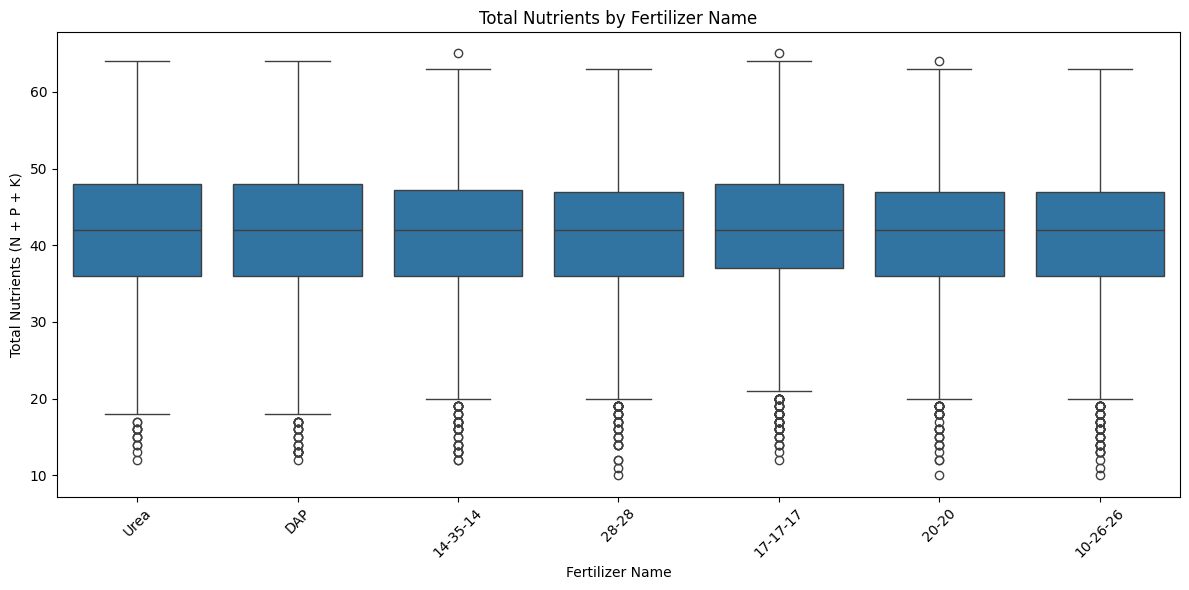

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_engineered,
    x="Fertilizer Name",
    y="Total_Nutrients"
)

plt.title("Total Nutrients by Fertilizer Name")
plt.xlabel("Fertilizer Name")
plt.ylabel("Total Nutrients (N + P + K)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

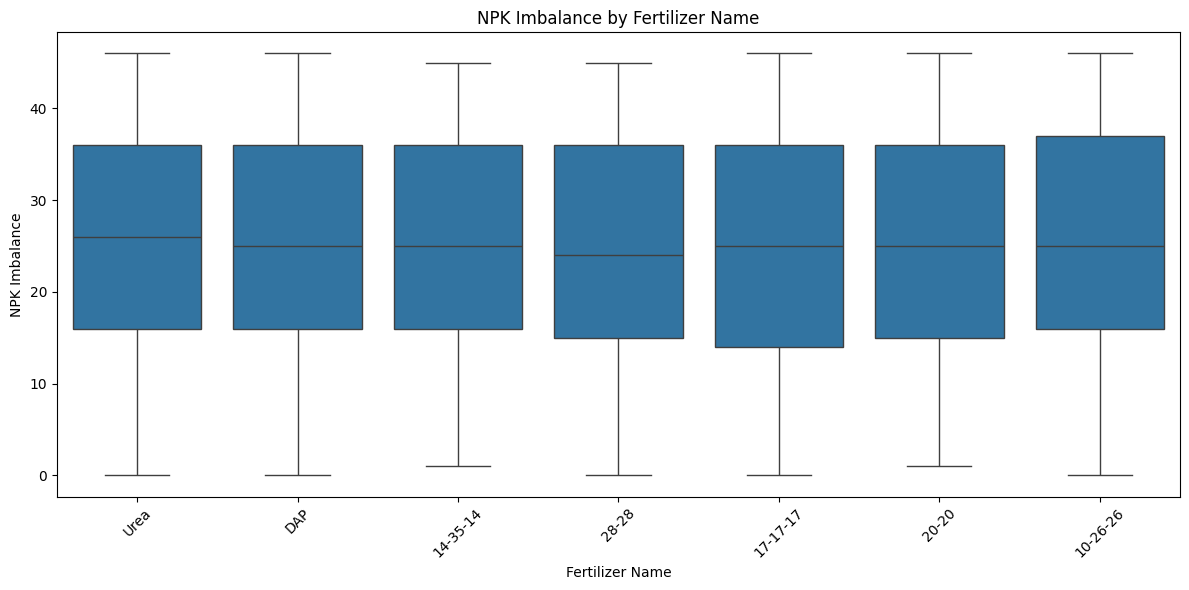

In [5]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_engineered,
    x="Fertilizer Name",
    y="NPK_Imbalance"
)

plt.title("NPK Imbalance by Fertilizer Name")
plt.xlabel("Fertilizer Name")
plt.ylabel("NPK Imbalance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()